# Assignment 3 — Link prediction on Cora + data-leakage investigation
No document-category labels are used for training (only for a post-hoc look at candidate links).

In [5]:
import sys; sys.path.append("../src")
import pandas as pd, torch
from data import load_cora, split_edges, leaky_mp_ei
from checks import assert_valid_split, assert_no_leak, assert_symmetric_decoder
from experiments import run_gnn, run_baseline, compare, summarize, failure_cases, top_candidates, seed_all
import viz
seed_all(0)

## 1. Split links (positives and negatives) and build the message-passing graph

unique links: 5278
train/val/test positives: 4488 263 527
val/test negatives      : 263 527
message-passing edges (train, both directions): 8976


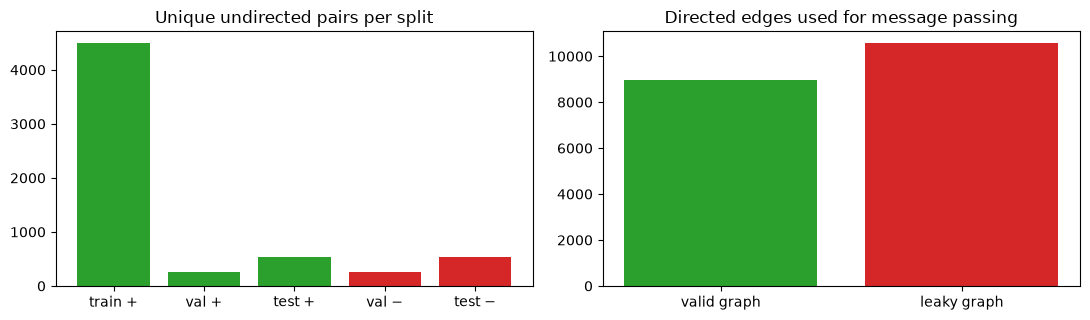

In [6]:
data = load_cora()
x, n = data.x, data.num_nodes
split = split_edges(data.edge_index, n, val=0.05, test=0.10, seed=0)
print("unique links:", split.all_pos_keys.numel())
print("train/val/test positives:", split.train_pos.size(1), split.val_pos.size(1), split.test_pos.size(1))
print("val/test negatives      :", split.val_neg.size(1), split.test_neg.size(1))
print("message-passing edges (train, both directions):", split.mp_ei.size(1))
viz.plot_split(split)

## 2. Automated leakage checks

In [7]:
assert_valid_split(split)          # disjoint splits, valid negatives, symmetric train-only graph
assert_no_leak(split)              # held-out links AND reverse copies absent from message-passing graph
print("all split / leakage checks PASSED")

# the checker must also CATCH a leaky graph:
try:
    assert_no_leak(split, leaky_mp_ei(split))
except AssertionError as e:
    print("leaky graph correctly rejected ->", e)

all split / leakage checks PASSED
leaky graph correctly rejected -> val_pos: link found in message-passing graph


## 2b. Choose weight decay on the validation set
Both settings are trained with the same split and seed, and compared on **validation AUC only**. The test set is not used for this choice.

In [8]:
rows = []
for wd in (5e-4, 0.0):
    for dec in ("dot", "mlp"):
        r = run_gnn(split, x, dec, split.mp_ei, wd=wd)
        rows.append(dict(weight_decay=wd, decoder=dec, val_auc=r["val_auc"]))   # VALIDATION only
pd.DataFrame(rows).round({"val_auc": 3})

,weight_decay,decoder,val_auc
0,0.0005,dot,0.775
1,0.0005,mlp,0.799
2,0.0000,dot,0.915
3,0.0000,mlp,0.951


## 3. Train both decoders + common-neighbour baseline (valid setting, seed 0)

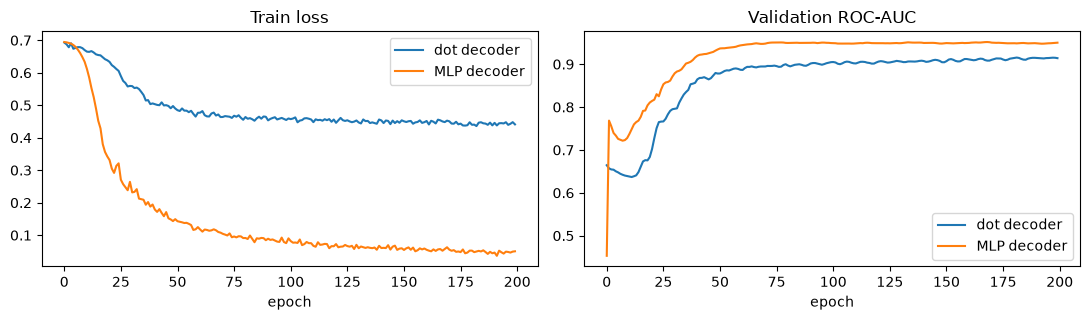

,val_auc,test_auc,test_ap
dot decoder,0.915,0.916,0.921
MLP decoder,0.952,0.949,0.955
common neighbors,0.712,0.721,0.719


In [9]:
runs = {"dot decoder": run_gnn(split, x, "dot", split.mp_ei),
        "MLP decoder": run_gnn(split, x, "mlp", split.mp_ei),
        "common neighbors": run_baseline(split, split.mp_ei)}
viz.plot_curves({k: v for k, v in runs.items() if "hist" in v})
pd.DataFrame({k: dict(val_auc=v["val_auc"], test_auc=v["test_auc"], test_ap=v["test_ap"]) for k, v in runs.items()}).T.round(3)

MLP decoder is symmetric on all test pairs


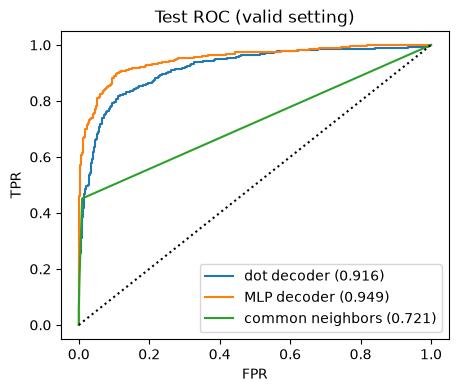

In [10]:
# decoder symmetry: score(u,v) == score(v,u)
m = runs["MLP decoder"]["model"].eval()
with torch.no_grad(): z = m.encode(x, split.mp_ei)
assert_symmetric_decoder(m, z, split.test_pos); assert_symmetric_decoder(m, z, split.test_neg)
print("MLP decoder is symmetric on all test pairs")
viz.plot_roc(runs)

## 4. Valid vs deliberately leaky experiment (3 seeds, fixed settings, NOT used for model selection)

test_auc        test_ap
setting method                                        
valid   common neighbors  0.721 ± 0.000  0.719 ± 0.000
        dot decoder       0.918 ± 0.001  0.922 ± 0.002
        MLP decoder       0.951 ± 0.001  0.955 ± 0.001
leaky   common neighbors  0.775 ± 0.000  0.771 ± 0.000
        dot decoder       0.969 ± 0.002  0.965 ± 0.003
        MLP decoder       0.996 ± 0.001  0.995 ± 0.001

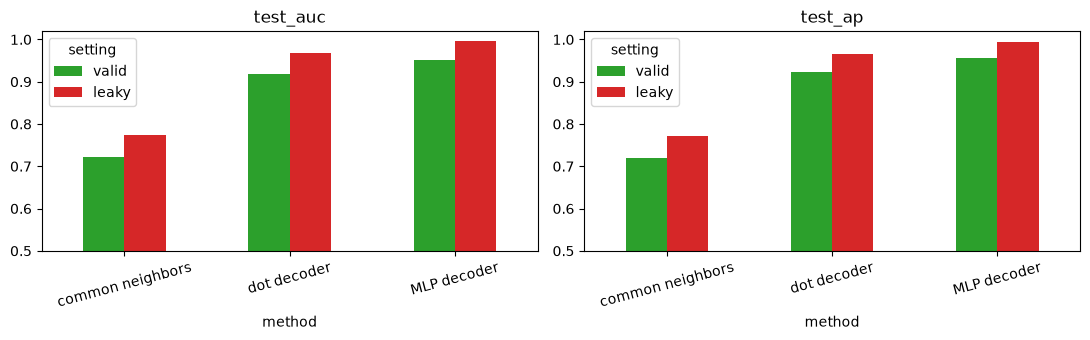

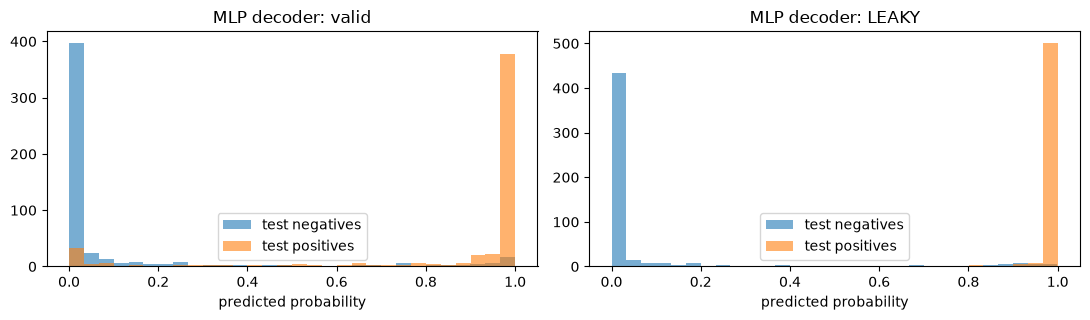

In [11]:
df, all_runs = compare(split, x, seeds=(0, 1, 2))
display(summarize(df))
viz.plot_valid_vs_leaky(df)
viz.plot_score_dist(all_runs[("valid", "MLP decoder")], all_runs[("leaky", "MLP decoder")])

**Why the leaky evaluation is invalid:** the held-out positive (u,v) is itself an edge in the graph the encoder sees, so u's and v's embeddings are built from each other. The model can "detect" the answer instead of predicting a *missing* link. A real new link would never be in the graph at prediction time. Leaky numbers are therefore inflated and must not be used to choose or report a model.

## 5. Failure cases (best decoder by **validation** AUC)

In [12]:
best = max(["dot decoder", "MLP decoder"], key=lambda k: runs[k]["val_auc"])
print("selected by validation:", best)
failure_cases(runs[best], split, k=5)

selected by validation: MLP decoder


,kind,u,v,score,train_deg_u,train_deg_v,common_nbrs
0,missed link,2066,2122,-16.07,3,9,0
1,missed link,2539,2632,-11.78,3,0,0
2,missed link,54,401,-10.98,1,3,0
3,missed link,311,1132,-10.88,3,0,0
4,missed link,2425,2426,-10.47,4,0,0
5,false alarm,1549,1955,8.35,2,6,0
6,false alarm,399,1782,5.61,4,7,0
7,false alarm,126,308,4.77,6,4,1
8,false alarm,725,1190,4.57,5,3,0
9,false alarm,1154,1546,4.49,8,5,0


## 6. Ten highly scored *unobserved* links

In [13]:
cand = top_candidates(runs[best]["model"], x, split, y=data.y, k=10)
cand

,u,v,prob,common_train_nbrs,class_u,class_v,same_class
0,306,1623,1.0,14,1,1,True
1,1701,1986,1.0,6,3,3,True
2,598,1701,1.0,8,3,3,True
3,1701,1810,1.0,0,3,3,True
4,1810,1986,1.0,2,3,3,True
5,598,1986,1.0,4,3,3,True
6,1810,2034,1.0,2,3,4,False
7,1986,2034,1.0,1,3,4,False
8,109,1623,1.0,6,1,1,True
9,358,1358,1.0,0,2,2,True


**Unobserved ≠ negative.** Absence of a citation in Cora only means it isn't recorded: the paper may be missing from the dataset, authors may not know each other's work, or the link may appear later. These are *candidates*: they need external validation (reading the papers, checking later citation data, domain expert review). Shared class is only weak supporting evidence, and labels were not used in training.

## 7. Overall conclusions
The learned MLP decoder is the best method: AUC 0.951, AP 0.955, versus 0.918 (dot) and 0.721 (common neighbours).
The GNN’s advantage over simple counting is large, because it uses node features and multi-hop structure.
Leakage inflates every method, and flexible models inflate the most (MLP error ≈12× smaller). Leaky numbers must not be used for selection or reported as performance.
Hard cases are cold-start nodes (all links hidden) and links between unrelated-looking papers. Both have no common neighbours.
The candidates are hypotheses. Unobserved doesn’t mean confirmed negative, so they need outside validation.



## 8. Automated tests

In [14]:
!pytest ../tests/test_assignment3.py -q

.............                                                            [100%]
============================== warnings summary ===============================
..\.venv\Lib\site-packages\torch\jit\_script.py:1491
  C:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
    warnings.warn(

tests/test_assignment3.py: 112 warnings
  C:\Users\PC\Documents\GNN-practical-assignments\.venv\Lib\site-packages\torch_geometric\inspector.py:433: DeprecationWarning: Failing to pass a value to the 'type_params' parameter of 'typing._eval_type' is deprecated, as it leads to incorrect behaviour when calling typing._eval_type on a stringified annotation that references a PEP 695 type parameter. It will be disallowed in Python 3.15.
    return typing._eval_type(value, _globals, None)  # type: ignore

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-war